# STEP 5c: Technical Analysis State Branch & Context-Blended Prediction (Horizon N=2)

## Architectural Role and Boundary Conditions
This notebook implements the **TA State Branch**, introducing deterministic, causal trend and phase state identification per candle and evaluating a soft context-blended prediction distribution.
- **Strict Invariance Contract:** All six existing base models, their training configurations, out-of-fold predictions, serialized model weights, the primary meta-model, and `master.csv` remain strictly unchanged.
- **Core Hypothesis:** Evaluates whether conditioning ML outputs on structural context ($T_{HAND}$ and $T_{LEARNED}$) improves directional accuracy over ML-only and meta-model baselines.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set path
PROJECT_ROOT = Path.cwd().resolve()
if (PROJECT_ROOT / "src").exists():
    ML_DIR = PROJECT_ROOT
elif (PROJECT_ROOT / "ML" / "src").exists():
    ML_DIR = PROJECT_ROOT / "ML"
else:
    ML_DIR = PROJECT_ROOT.parent

if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import config
from src.column_dictionary import load_master
from src.ta_state import compute_ta_state, TA_STATE_CSV_GZ, derive_break_direction
from src.context_blend import (
    T_HAND, check_t_hand_symmetry, synthesize_ml_distribution,
    compute_soft_blend, fit_learned_table, select_w_nested
)
from src.io_utils import load_horizon_oof_csv_gz

HORIZON = 2
df_train = load_master(split="train")
df_valid_candles = df_train.iloc[2018:].copy()

print("=" * 80)
print("SECTION 1: COLUMN CHECK & DEFINITIONS ON TRAIN ROWS (POST-WARMUP)")
print("=" * 80)

cols_check = [
    "feat_struct_trend_up", "feat_struct_trend_down", "feat_struct_trend_range",
    "feat_struct_trend_age", "feat_struct_pullback_depth_atr", "feat_struct_bars_since_break",
    "feat_struct_bars_since_retest", "feat_struct_retest_direction", "feat_struct_dist_support_atr",
    "feat_struct_dist_resistance_atr", "feat_ma_alignment_ema_5m", "feat_ma_alignment_ema_1h", "feat_mom_adx_14"
]

for col in cols_check:
    s = df_valid_candles[col]
    print(f"{col:<33}: min={s.min():<8.4f} median={s.median():<8.4f} max={s.max():<8.4f} missing={s.isna().sum()}")

print("\n[Definitions & Invariants]")
print("- feat_struct_trend_up/down/range: Dow rule swing trend state (binary {0, 1}).")
print("- feat_struct_trend_age: Elapsed candles since trend regime started.")
print("- feat_struct_pullback_depth_atr: Retracement against trend from last swing extreme in ATR units.")
print("- feat_struct_bars_since_break: Candles since last S/R break (placeholder 9999 = uninitialized/no prior event).")
print("- feat_struct_retest_direction: Retest polarity (+1 bullish holding, -1 bearish holding, 0 otherwise).")
print("- feat_ma_alignment_ema_5m/1h: Pairwise EMA alignment hierarchy score in [-1, 1].")
print("- feat_mom_adx_14: Normalized ADX trend strength in [0, 1].")
print("- Break Direction: Not in master.csv; causally derived via read-only derive_break_direction().")

SECTION 1: COLUMN CHECK & DEFINITIONS ON TRAIN ROWS (POST-WARMUP)
feat_struct_trend_up             : min=0.0000   median=0.0000   max=1.0000   missing=0
feat_struct_trend_down           : min=0.0000   median=0.0000   max=1.0000   missing=0
feat_struct_trend_range          : min=0.0000   median=0.0000   max=1.0000   missing=0
feat_struct_trend_age            : min=0.0000   median=12.0000  max=249.0000 missing=0
feat_struct_pullback_depth_atr   : min=0.0000   median=0.8531   max=22.3051  missing=0
feat_struct_bars_since_break     : min=0.0000   median=0.0000   max=17.0000  missing=0
feat_struct_bars_since_retest    : min=0.0000   median=5.0000   max=114.0000 missing=0
feat_struct_retest_direction     : min=-1.0000  median=0.0000   max=1.0000   missing=0
feat_struct_dist_support_atr     : min=0.0000   median=0.6916   max=43.4167  missing=0
feat_struct_dist_resistance_atr  : min=0.0000   median=0.6826   max=16.3031  missing=0
feat_ma_alignment_ema_5m         : min=-1.0000  median=0.0000   

SECTION 2: TA STATE DATASET & CONTEXT DISTRIBUTION


First 20 rows of ta_state.csv.gz:


,open_time,ta_trend_label,ta_trend_strength,ta_trend_p_up,ta_phase_label,ta_phase_strength,ta_phase_p_pullback,ta_context
2018,2023-11-08 00:10:00+00:00,DOWN,0.12,0.44,PULLBACK,0.0000,0.5000,DOWNTREND | PULLBACK
2019,2023-11-08 00:15:00+00:00,DOWN,0.18,0.41,PULLBACK,0.0000,0.5000,DOWNTREND | PULLBACK
2020,2023-11-08 00:20:00+00:00,DOWN,0.24,0.38,BREAKTHROUGH,0.1217,0.4391,DOWNTREND | BREAKTHROUGH
2021,2023-11-08 00:25:00+00:00,DOWN,0.30,0.35,BREAKTHROUGH,0.1269,0.4366,DOWNTREND | BREAKTHROUGH
2022,2023-11-08 00:30:00+00:00,DOWN,0.30,0.35,BREAKTHROUGH,0.4047,0.2977,DOWNTREND | BREAKTHROUGH
2023,2023-11-08 00:35:00+00:00,DOWN,0.30,0.35,BREAKTHROUGH,0.3328,0.3336,DOWNTREND | BREAKTHROUGH
2024,2023-11-08 00:40:00+00:00,DOWN,0.30,0.35,BREAKTHROUGH,0.1007,0.4496,DOWNTREND | BREAKTHROUGH
2025,2023-11-08 00:45:00+00:00,DOWN,0.36,0.32,BREAKTHROUGH,0.1179,0.4411,DOWNTREND | BREAKTHROUGH
2026,2023-11-08 00:50:00+00:00,DOWN,0.36,0.32,PULLBACK,0.0000,0.5000,DOWNTREND | PULLBACK
2027,2023-11-08 00:55:00+00:00,DOWN,0.36,0.32,PULLBACK,0.0000,0.5000,DOWNTREND | PULLBACK



Distribution of Four Canonical Contexts (Train Partition):


,Context,Candle Count,Share (%)
0,UPTREND | BREAKTHROUGH,66131,30.205769
1,DOWNTREND | BREAKTHROUGH,56643,25.872062
2,UPTREND | PULLBACK,51263,23.414712
3,DOWNTREND | PULLBACK,44898,20.507457


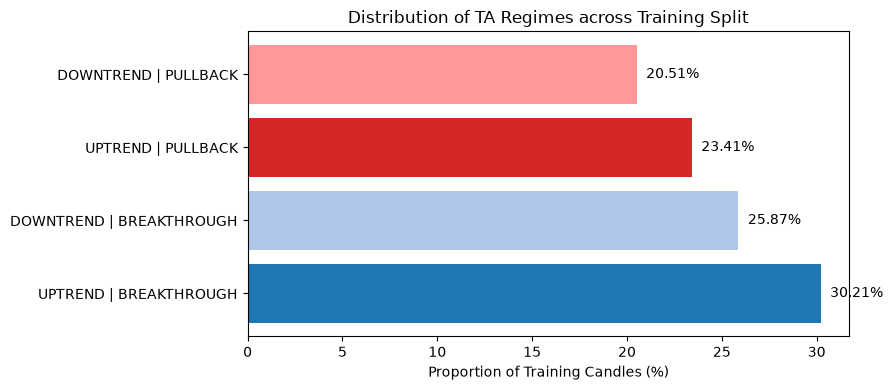

In [2]:
print("=" * 80)
print("SECTION 2: TA STATE DATASET & CONTEXT DISTRIBUTION")
print("=" * 80)

ta_state_df = pd.read_csv(TA_STATE_CSV_GZ)
ta_state_df["open_time"] = pd.to_datetime(ta_state_df["open_time"], utc=True)
ta_state_train = ta_state_df.iloc[2018:len(df_train)].copy()

print("First 20 rows of ta_state.csv.gz:")
display(ta_state_train.head(20))

print("\nDistribution of Four Canonical Contexts (Train Partition):")
ctx_counts = ta_state_train["ta_context"].value_counts()
ctx_shares = ta_state_train["ta_context"].value_counts(normalize=True) * 100.0

df_ctx_summary = pd.DataFrame({
    "Context": ctx_counts.index,
    "Candle Count": ctx_counts.values,
    "Share (%)": ctx_shares.values
})
display(df_ctx_summary)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(df_ctx_summary["Context"], df_ctx_summary["Share (%)"], color=["#1f77b4", "#aec7e8", "#d62728", "#ff9896"])
ax.set_xlabel("Proportion of Training Candles (%)")
ax.set_title("Distribution of TA Regimes across Training Split")
for i, v in enumerate(df_ctx_summary["Share (%)"]):
    ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
plt.tight_layout()
plt.show()

In [3]:
print("=" * 80)
print("SECTION 3: T_HAND SYMMETRY & ML BASE DISTRIBUTION SYNTHESIS")
print("=" * 80)

# 1. Symmetry test
is_sym = check_t_hand_symmetry()
print(f"T_HAND Mirror Symmetry Check: {'PASSED (Exact mathematical symmetry verified)' if is_sym else 'FAILED'}")
assert is_sym, "T_HAND must be mirror symmetric"

# 2. Display T_HAND
hand_rows = []
for (trend, phase, ml_cls), out_cls in sorted(T_HAND.items()):
    cls_str = {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[ml_cls]
    out_str = {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[out_cls]
    hand_rows.append({
        "Trend": trend,
        "Phase": phase,
        "ML Signal": cls_str,
        "T_HAND Output": out_str
    })
df_t_hand = pd.DataFrame(hand_rows)
display(df_t_hand)

# 3. Load OOF predictions for Base Models
oof_dir = config.RESULTS_DIR / "oof"
bin_oofs = {
    "binary_lr": load_horizon_oof_csv_gz(oof_dir / f"binary_lr_N{HORIZON}.csv.gz"),
    "binary_rf": load_horizon_oof_csv_gz(oof_dir / f"binary_rf_N{HORIZON}.csv.gz"),
    "binary_gb": load_horizon_oof_csv_gz(oof_dir / f"binary_gb_N{HORIZON}.csv.gz"),
}
tri_oofs = {
    "three_class_lr": load_horizon_oof_csv_gz(oof_dir / f"three_class_lr_N{HORIZON}.csv.gz"),
    "three_class_rf": load_horizon_oof_csv_gz(oof_dir / f"three_class_rf_N{HORIZON}.csv.gz"),
    "three_class_gb": load_horizon_oof_csv_gz(oof_dir / f"three_class_gb_N{HORIZON}.csv.gz"),
}

ml_dist_df = synthesize_ml_distribution(bin_oofs, tri_oofs)
print(f"\nSynthesized ML Base Distribution (p_ml) across {len(ml_dist_df):,} out-of-fold candles.")
display(ml_dist_df.head())

# Merge into unified evaluation dataframe
merged_eval = ml_dist_df.merge(ta_state_train, on="open_time", how="inner")
extra_cols = [
    f"raw_sign_{HORIZON}",
    f"target_{HORIZON}_S1",
    "feat_struct_rule_vote",
    "feat_mom_rsi_14",
    f"fwd_ret_open_{HORIZON}"
]
extra_df = df_train[extra_cols].copy().reset_index()
extra_df["open_time"] = pd.to_datetime(extra_df["open_time"], utc=True)
merged_eval = merged_eval.merge(extra_df, on="open_time", how="inner")
print(f"Merged Evaluation Population: {len(merged_eval):,} rows.")

SECTION 3: T_HAND SYMMETRY & ML BASE DISTRIBUTION SYNTHESIS
T_HAND Mirror Symmetry Check: PASSED (Exact mathematical symmetry verified)


,Trend,Phase,ML Signal,T_HAND Output
0,DOWN,BREAKTHROUGH,DOWN,DOWN
1,DOWN,BREAKTHROUGH,NEUTRAL,DOWN
2,DOWN,BREAKTHROUGH,UP,NEUTRAL
3,DOWN,PULLBACK,DOWN,NEUTRAL
4,DOWN,PULLBACK,NEUTRAL,UP
5,DOWN,PULLBACK,UP,UP
6,UP,BREAKTHROUGH,DOWN,NEUTRAL
7,UP,BREAKTHROUGH,NEUTRAL,UP
8,UP,BREAKTHROUGH,UP,UP
9,UP,PULLBACK,DOWN,DOWN



Synthesized ML Base Distribution (p_ml) across 132,521 out-of-fold candles.


,open_time,fold,p_down_ml,p_neutral_ml,p_up_ml,ml_pred
0,2024-09-03 01:10:00+00:00,1,0.369170,0.306168,0.324662,-1
1,2024-09-03 01:15:00+00:00,1,0.360684,0.327543,0.311773,-1
2,2024-09-03 01:20:00+00:00,1,0.340066,0.344473,0.315461,0
3,2024-09-03 01:25:00+00:00,1,0.350899,0.339421,0.309680,-1
4,2024-09-03 01:30:00+00:00,1,0.343382,0.351280,0.305338,0


Merged Evaluation Population: 132,521 rows.


SECTION 4: FOUR WINDOW VISUALIZATIONS (288 CANDLES EACH)


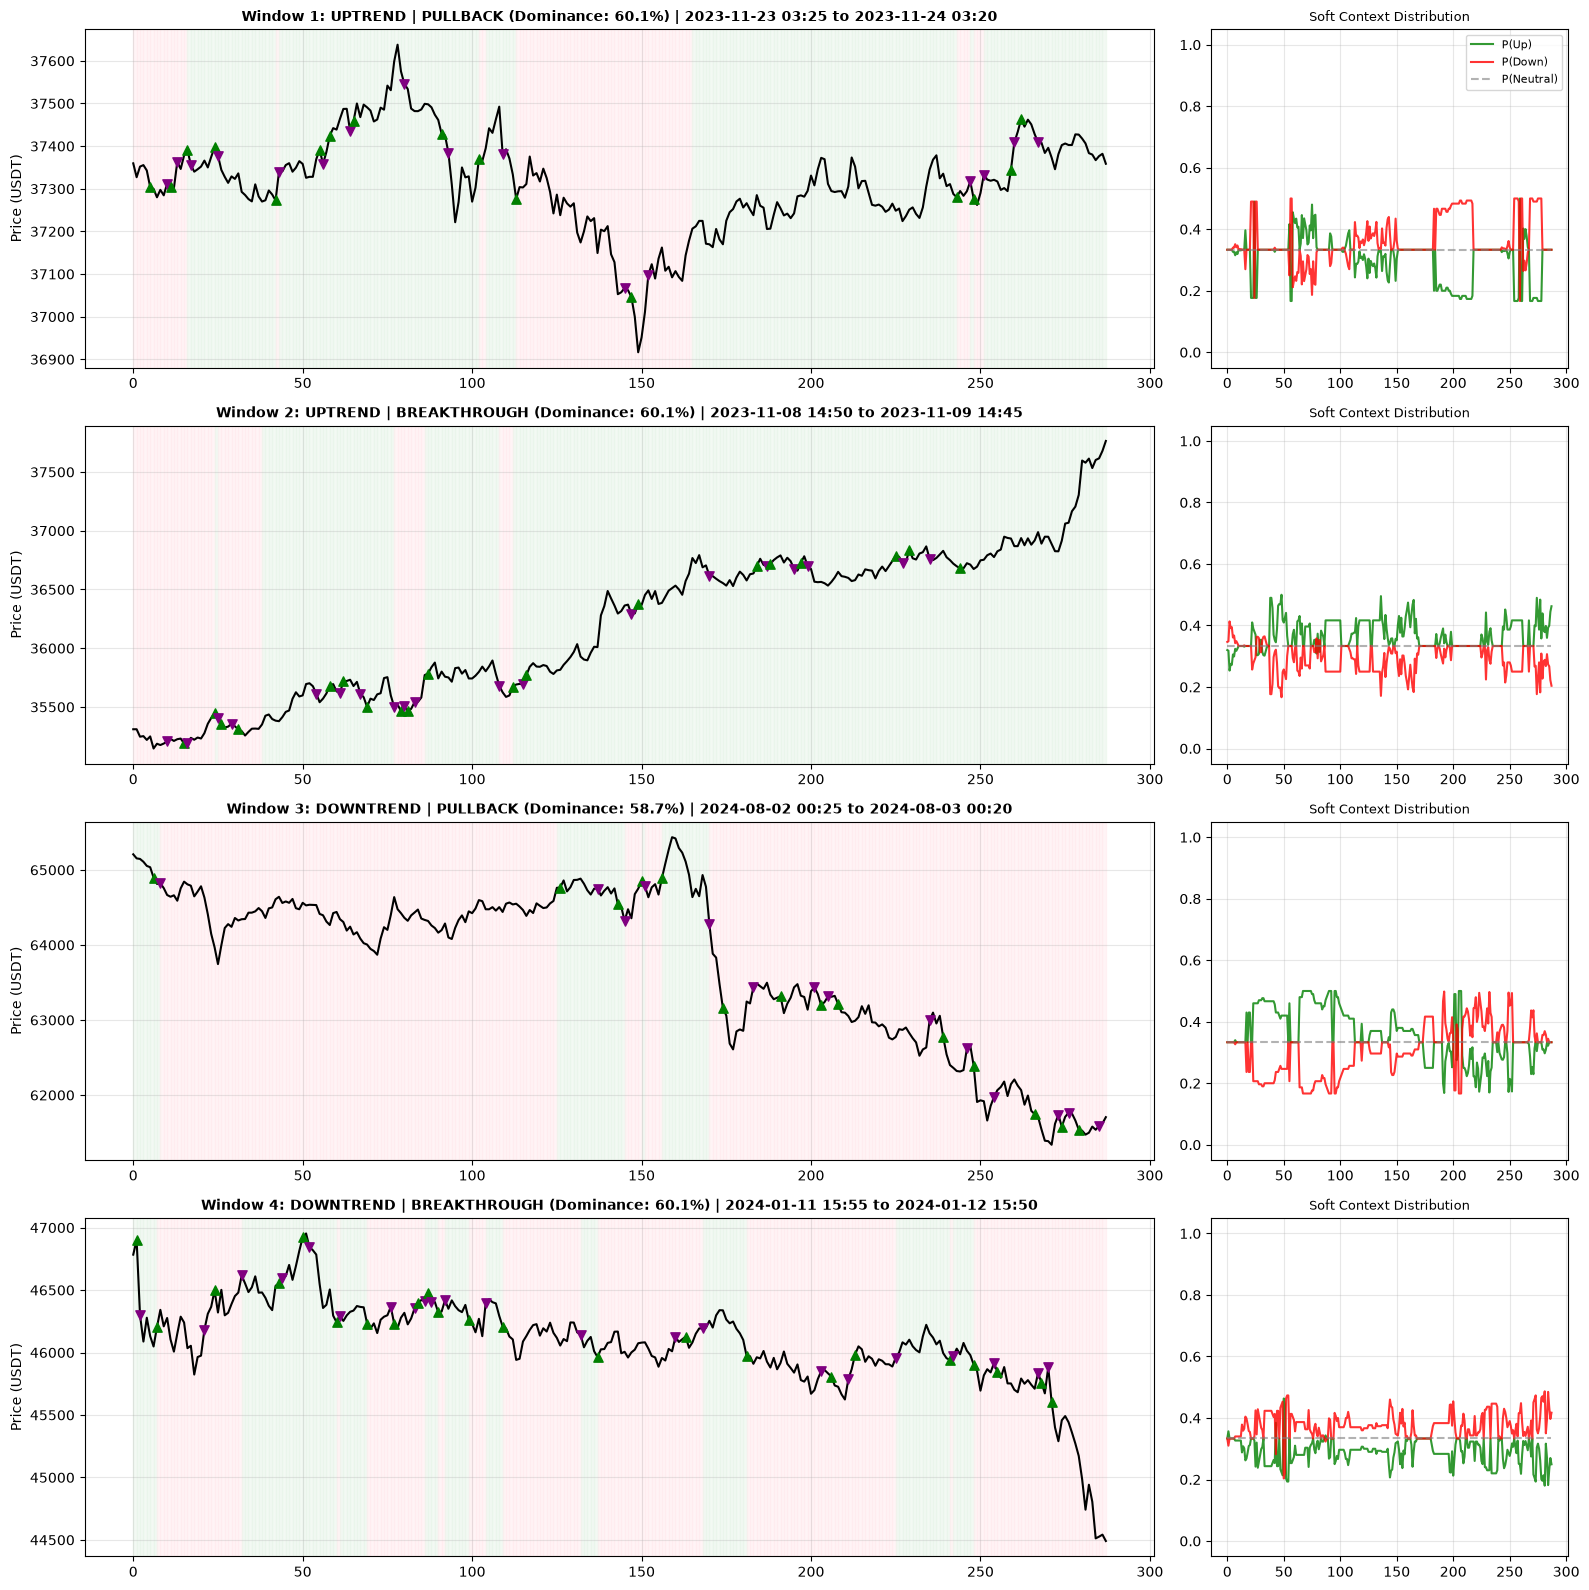

Visualization Note: Shaded by Trend (Green=Uptrend, Red=Downtrend); markers indicate Phase changes (^=Breakthrough, v=Pullback).


In [4]:
print("=" * 80)
print("SECTION 4: FOUR WINDOW VISUALIZATIONS (288 CANDLES EACH)")
print("=" * 80)

contexts_to_plot = [
    "UPTREND | PULLBACK",
    "UPTREND | BREAKTHROUGH",
    "DOWNTREND | PULLBACK",
    "DOWNTREND | BREAKTHROUGH"
]

target_windows = {}
w_len = 288

for ctx in contexts_to_plot:
    # Rule: First window of 288 candles where dominant context share > 60%
    rolling_ctx = (ta_state_train["ta_context"] == ctx).astype(int).rolling(w_len).mean()
    valid_starts = np.where(rolling_ctx >= 0.60)[0]
    if len(valid_starts) > 0:
        end_idx = valid_starts[0]
        start_idx = end_idx - w_len + 1
        target_windows[ctx] = (start_idx, end_idx)
    else:
        max_idx = rolling_ctx.argmax()
        target_windows[ctx] = (max_idx - w_len + 1, max_idx)

fig, axes = plt.subplots(4, 2, figsize=(16, 16), gridspec_kw={"width_ratios": [3, 1]})

for i, (ctx, (s_idx, e_idx)) in enumerate(target_windows.items()):
    ax_price = axes[i, 0]
    ax_pred = axes[i, 1]
    
    sub_df = df_train.iloc[2018:].iloc[s_idx:e_idx+1].copy()
    sub_ta = ta_state_train.iloc[s_idx:e_idx+1].copy()
    
    t_axis = np.arange(len(sub_df))
    close_prices = sub_df["close"].values
    
    # 1. Price Plot
    ax_price.plot(t_axis, close_prices, color="black", linewidth=1.5, label="BTC Close (5m)")
    
    # Background colour by trend
    for j in range(len(t_axis)-1):
        tr = sub_ta["ta_trend_label"].iloc[j]
        color = "#e8f5e9" if tr == "UP" else "#ffebee"
        ax_price.axvspan(t_axis[j], t_axis[j+1], color=color, alpha=0.5, edgecolor=None)
        
    # Markers at phase changes
    phase_changes = np.where(sub_ta["ta_phase_label"].values[:-1] != sub_ta["ta_phase_label"].values[1:])[0] + 1
    for pc in phase_changes:
        ph = sub_ta["ta_phase_label"].iloc[pc]
        marker = "^" if ph == "BREAKTHROUGH" else "v"
        m_color = "green" if ph == "BREAKTHROUGH" else "purple"
        ax_price.scatter(t_axis[pc], close_prices[pc], marker=marker, color=m_color, s=45, zorder=5)
        
    actual_share = (sub_ta["ta_context"] == ctx).mean() * 100.0
    start_time = str(sub_df.index[0])[:16]
    end_time = str(sub_df.index[-1])[:16]
    ax_price.set_title(f"Window {i+1}: {ctx} (Dominance: {actual_share:.1f}%) | {start_time} to {end_time}", fontsize=10, fontweight="bold")
    ax_price.set_ylabel("Price (USDT)")
    ax_price.grid(True, alpha=0.3)
    
    # 2. Blended Prediction Beneath / Beside
    # Compute soft blend probabilities for this slice with T_HAND (w=0.5)
    t_up_w = sub_ta["ta_trend_p_up"].values
    f_pb_w = sub_ta["ta_phase_p_pullback"].values
    p_ml_w = np.full((len(sub_df), 3), 1.0 / 3.0) # uniform prior
    _, p_final_w = compute_soft_blend(t_up_w, f_pb_w, p_ml_w, T_HAND, w=0.5)
    
    ax_pred.plot(t_axis, p_final_w[:, 2], color="green", label="P(Up)", alpha=0.8)
    ax_pred.plot(t_axis, p_final_w[:, 0], color="red", label="P(Down)", alpha=0.8)
    ax_pred.plot(t_axis, p_final_w[:, 1], color="gray", linestyle="--", label="P(Neutral)", alpha=0.6)
    ax_pred.set_title("Soft Context Distribution", fontsize=9)
    ax_pred.set_ylim(-0.05, 1.05)
    ax_pred.grid(True, alpha=0.3)
    if i == 0:
        ax_pred.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()
print("Visualization Note: Shaded by Trend (Green=Uptrend, Red=Downtrend); markers indicate Phase changes (^=Breakthrough, v=Pullback).")

In [5]:
print("=" * 80)
print("SECTION 5: CONTEXT CELL ANALYSIS (12 CELLS: EMPIRICAL OUTCOMES & CIRCULAR-SHIFT)")
print("=" * 80)

context_analysis = []
np.random.seed(42)

for (trend, phase, ml_cls), hand_out in sorted(T_HAND.items()):
    mask = (
        (merged_eval["ta_trend_label"] == trend)
        & (merged_eval["ta_phase_label"] == phase)
        & (merged_eval["ml_pred"] == ml_cls)
    )
    sub = merged_eval[mask]
    n_cell = len(sub)
    share = n_cell / len(merged_eval) * 100.0
    
    y = sub[f"raw_sign_{HORIZON}"].values
    valid_y = y[y != 0]
    
    if len(valid_y) > 0:
        up_share = (valid_y == 1).mean() * 100.0
        # Block-bootstrap 95% CI (B=500, block 288)
        B = 500
        block_len = 288
        n_blocks = max(1, len(valid_y) // block_len)
        boot_shares = []
        for _ in range(B):
            b_indices = np.random.randint(0, n_blocks, size=n_blocks)
            sampled_idx = np.concatenate([np.arange(b * block_len, min((b+1)*block_len, len(valid_y))) for b in b_indices])
            boot_shares.append((valid_y[sampled_idx] == 1).mean() * 100.0)
        ci_lower = np.percentile(boot_shares, 2.5)
        ci_upper = np.percentile(boot_shares, 97.5)
        
        # Circular shift test (200 shifts, min shift 2018)
        shift_shares = []
        full_y = merged_eval[f"raw_sign_{HORIZON}"].values
        mask_idx = np.where(mask)[0]
        n_tot = len(full_y)
        for s in range(200):
            shift = 2018 + s * 137
            shifted_y = np.roll(full_y, shift)[mask_idx]
            v_shift = shifted_y[shifted_y != 0]
            if len(v_shift) > 0:
                shift_shares.append((v_shift == 1).mean() * 100.0)
        circ_low = np.percentile(shift_shares, 2.5) if shift_shares else np.nan
        circ_high = np.percentile(shift_shares, 97.5) if shift_shares else np.nan
    else:
        up_share = ci_lower = ci_upper = circ_low = circ_high = np.nan

    maj_dir = "UP" if up_share > 50.0 else ("DOWN" if up_share < 50.0 else "FLAT")
    hand_str = {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[hand_out]
    matches = (hand_str == maj_dir)

    context_analysis.append({
        "Trend": trend,
        "Phase": phase,
        "ML Signal": {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[ml_cls],
        "Row Share %": share,
        "UP Outcome %": up_share,
        "95% Boot CI": f"[{ci_lower:.2f}%, {ci_upper:.2f}%]",
        "Circular Null Band": f"[{circ_low:.2f}%, {circ_high:.2f}%]",
        "T_HAND Call": hand_str,
        "Matches Majority": "YES" if matches else "NO"
    })

df_cell_eval = pd.DataFrame(context_analysis)
display(df_cell_eval)

SECTION 5: CONTEXT CELL ANALYSIS (12 CELLS: EMPIRICAL OUTCOMES & CIRCULAR-SHIFT)


,Trend,Phase,ML Signal,Row Share %,UP Outcome %,95% Boot CI,Circular Null Band,T_HAND Call,Matches Majority
0,DOWN,BREAKTHROUGH,DOWN,1.667660,49.411765,"[47.12%, 51.59%]","[47.51%, 51.97%]",DOWN,YES
1,DOWN,BREAKTHROUGH,NEUTRAL,11.049570,51.025992,"[50.06%, 51.94%]","[49.06%, 50.76%]",DOWN,NO
2,DOWN,BREAKTHROUGH,UP,14.267927,52.205882,"[51.19%, 53.08%]","[49.25%, 50.78%]",NEUTRAL,NO
3,DOWN,PULLBACK,DOWN,3.825809,48.086030,"[46.46%, 49.53%]","[48.57%, 51.52%]",NEUTRAL,NO
4,DOWN,PULLBACK,NEUTRAL,10.334211,50.533548,"[49.47%, 51.66%]","[49.21%, 50.68%]",UP,YES
5,DOWN,PULLBACK,UP,5.722112,51.451187,"[50.53%, 52.48%]","[48.79%, 51.09%]",UP,YES
6,UP,BREAKTHROUGH,DOWN,13.669532,47.202739,"[46.30%, 48.02%]","[49.28%, 50.68%]",NEUTRAL,NO
7,UP,BREAKTHROUGH,NEUTRAL,13.833279,48.370010,"[47.73%, 49.17%]","[49.26%, 50.71%]",UP,NO
8,UP,BREAKTHROUGH,UP,2.661465,52.709220,"[51.30%, 54.27%]","[48.31%, 51.61%]",UP,YES
9,UP,PULLBACK,DOWN,4.394775,49.733723,"[48.03%, 51.59%]","[48.58%, 51.55%]",DOWN,YES


In [6]:
print("=" * 80)
print("SECTION 6: NESTED WALK-FORWARD w SELECTION & T_LEARNED PER FOLD")
print("=" * 80)

eval_folds = [2, 3, 4, 5, 6]

# 1. Optimal w selection per fold for T_HAND
chosen_w_hand = select_w_nested(merged_eval, eval_folds=eval_folds, table=T_HAND, use_context_strength=False)
chosen_w_ctx = select_w_nested(merged_eval, eval_folds=eval_folds, table=T_HAND, use_context_strength=True)

# 2. Fit T_LEARNED per fold
learned_tables = {}
for k in eval_folds:
    df_prior = merged_eval[merged_eval["fold"] < k]
    learned_tables[k] = fit_learned_table(df_prior)

chosen_w_learned = {}
for k in eval_folds:
    w_k = select_w_nested(merged_eval, eval_folds=[k], table=learned_tables[k], use_context_strength=False)[k]
    chosen_w_learned[k] = w_k

fold_w_summary = []
for k in eval_folds:
    fold_w_summary.append({
        "Fold": k,
        "Held-Out Rows": (merged_eval["fold"] == k).sum(),
        "Optimal w (T_HAND)": chosen_w_hand[k],
        "Optimal w (T_HAND w_ctx)": chosen_w_ctx[k],
        "Optimal w (T_LEARNED)": chosen_w_learned[k],
    })

df_w_summary = pd.DataFrame(fold_w_summary)
print("Nested Walk-Forward Optimal Blending Weight w (Evaluated on Earlier Folds Only):")
display(df_w_summary)

# Display T_LEARNED side by side with T_HAND
learned_comp_rows = []
for key in sorted(T_HAND.keys()):
    tr, ph, ml = key
    row = {
        "Trend": tr,
        "Phase": ph,
        "ML Signal": {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[ml],
        "T_HAND": {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[T_HAND[key]]
    }
    for k in eval_folds:
        row[f"T_LEARNED Fold {k}"] = {-1: "DOWN", 0: "NEUTRAL", 1: "UP"}[learned_tables[k][key]]
    learned_comp_rows.append(row)

df_learned_comp = pd.DataFrame(learned_comp_rows)
print("\nComparison of T_HAND vs T_LEARNED per Walk-Forward Fold:")
display(df_learned_comp)

SECTION 6: NESTED WALK-FORWARD w SELECTION & T_LEARNED PER FOLD


Nested Walk-Forward Optimal Blending Weight w (Evaluated on Earlier Folds Only):


,Fold,Held-Out Rows,Optimal w (T_HAND),Optimal w (T_HAND w_ctx),Optimal w (T_LEARNED)
0,2,22087,0.0,0.0,0.0
1,3,22087,0.0,0.0,0.0
2,4,22087,0.0,0.0,0.0
3,5,22087,0.0,0.0,0.0
4,6,22085,0.0,0.0,0.0



Comparison of T_HAND vs T_LEARNED per Walk-Forward Fold:


,Trend,Phase,ML Signal,T_HAND,T_LEARNED Fold 2,T_LEARNED Fold 3,T_LEARNED Fold 4,T_LEARNED Fold 5,T_LEARNED Fold 6
0,DOWN,BREAKTHROUGH,DOWN,DOWN,UP,NEUTRAL,DOWN,DOWN,DOWN
1,DOWN,BREAKTHROUGH,NEUTRAL,DOWN,UP,UP,UP,UP,UP
2,DOWN,BREAKTHROUGH,UP,NEUTRAL,UP,UP,UP,UP,UP
3,DOWN,PULLBACK,DOWN,NEUTRAL,DOWN,DOWN,DOWN,DOWN,DOWN
4,DOWN,PULLBACK,NEUTRAL,UP,UP,NEUTRAL,UP,NEUTRAL,NEUTRAL
5,DOWN,PULLBACK,UP,UP,UP,UP,NEUTRAL,UP,UP
6,UP,BREAKTHROUGH,DOWN,NEUTRAL,DOWN,DOWN,DOWN,DOWN,DOWN
7,UP,BREAKTHROUGH,NEUTRAL,UP,DOWN,DOWN,DOWN,DOWN,DOWN
8,UP,BREAKTHROUGH,UP,UP,UP,UP,UP,UP,UP
9,UP,PULLBACK,DOWN,DOWN,UP,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL


In [7]:
print("=" * 80)
print("SECTION 7: OUT-OF-FOLD PERFORMANCE EVALUATION (FOLDS 2 TO 6)")
print("=" * 80)

# Filter evaluation population to folds 2..6
eval_mask = merged_eval["fold"].isin(eval_folds)
df_eval = merged_eval[eval_mask].copy()

t_up = df_eval["ta_trend_p_up"].values
f_pb = df_eval["ta_phase_p_pullback"].values
p_ml = df_eval[["p_down_ml", "p_neutral_ml", "p_up_ml"]].values
tr_s = df_eval["ta_trend_strength"].values
ph_s = df_eval["ta_phase_strength"].values
y_raw = df_eval[f"raw_sign_{HORIZON}"].values
truth_target_col = f"target_{HORIZON}_S1"
y_s1 = df_eval[truth_target_col].values

# 1. ML Only
p_final_ml = p_ml

# 2. Meta-Model
meta_oof = load_horizon_oof_csv_gz(config.RESULTS_DIR / "oof" / f"meta_N{HORIZON}.csv.gz")
meta_oof["open_time"] = pd.to_datetime(meta_oof["open_time"], utc=True)
meta_merged = df_eval[["open_time"]].merge(meta_oof, on="open_time", how="left")
p_final_meta = meta_merged[["p_down", "p_neutral", "p_up"]].values

# 3. T_HAND blend with chosen fold w
p_final_hand = np.zeros_like(p_ml)
for k in eval_folds:
    k_idx = np.where(df_eval["fold"].values == k)[0]
    w_k = chosen_w_hand[k]
    _, p_k = compute_soft_blend(t_up[k_idx], f_pb[k_idx], p_ml[k_idx], T_HAND, w=w_k)
    p_final_hand[k_idx] = p_k

# 4. T_HAND blend with w_ctx
p_final_ctx = np.zeros_like(p_ml)
for k in eval_folds:
    k_idx = np.where(df_eval["fold"].values == k)[0]
    w_k = chosen_w_ctx[k]
    _, p_k = compute_soft_blend(t_up[k_idx], f_pb[k_idx], p_ml[k_idx], T_HAND, w=w_k,
                                trend_strength=tr_s[k_idx], phase_strength=ph_s[k_idx], use_context_strength=True)
    p_final_ctx[k_idx] = p_k

# 5. T_LEARNED blend
p_final_learned = np.zeros_like(p_ml)
for k in eval_folds:
    k_idx = np.where(df_eval["fold"].values == k)[0]
    w_k = chosen_w_learned[k]
    _, p_k = compute_soft_blend(t_up[k_idx], f_pb[k_idx], p_ml[k_idx], learned_tables[k], w=w_k)
    p_final_learned[k_idx] = p_k

# 6. Table only (w=1.0)
_, p_final_table_hand = compute_soft_blend(t_up, f_pb, p_ml, T_HAND, w=1.0)
p_final_table_learned = np.zeros_like(p_ml)
for k in eval_folds:
    k_idx = np.where(df_eval["fold"].values == k)[0]
    _, p_k = compute_soft_blend(t_up[k_idx], f_pb[k_idx], p_ml[k_idx], learned_tables[k], w=1.0)
    p_final_table_learned[k_idx] = p_k

# 7. Previous TA Composite & RSI reversal rule
prev_ta_pred = np.where(df_eval["feat_struct_rule_vote"].values == 1, 1,
                        np.where(df_eval["feat_struct_rule_vote"].values == -1, -1, 0))
rsi_pred = np.where(df_eval["feat_mom_rsi_14"].values > 0.70, -1,
                    np.where(df_eval["feat_mom_rsi_14"].values < 0.30, 1, 0))

def to_prob_matrix(preds):
    probs = np.zeros((len(preds), 3), dtype=float)
    for idx_c, c_val in enumerate([-1, 0, 1]):
        probs[preds == c_val, idx_c] = 1.0
    return probs

models_dict = {
    "ML Only (p_ml)": p_final_ml,
    "Meta-Model (baseline)": p_final_meta,
    "T_HAND Blend (w)": p_final_hand,
    "T_HAND Blend (w_ctx)": p_final_ctx,
    "T_LEARNED Blend": p_final_learned,
    "Table Only (T_HAND, w=1)": p_final_table_hand,
    "Table Only (T_LEARNED, w=1)": p_final_table_learned,
    "RSI-14 Reversal Rule": to_prob_matrix(rsi_pred),
    "Previous TA Composite": to_prob_matrix(prev_ta_pred),
}

from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

eval_results = []
fwd_ret = df_eval[f"fwd_ret_open_{HORIZON}"].values
cost_c = config.COST

def bootstrap_accuracy(y_true, y_pred, B=500, block_len=288):
    valid = (y_true != 0) & (y_pred != 0)
    if valid.sum() == 0:
        return np.nan, np.nan, np.nan
    y_t = y_true[valid]
    y_p = y_pred[valid]
    acc = (y_t == y_p).mean() * 100.0
    n_blocks = max(1, len(y_t) // block_len)
    boots = []
    for _ in range(B):
        b_idx = np.random.randint(0, n_blocks, size=n_blocks)
        s_idx = np.concatenate([np.arange(b * block_len, min((b+1)*block_len, len(y_t))) for b in b_idx])
        boots.append((y_t[s_idx] == y_p[s_idx]).mean() * 100.0)
    return acc, np.percentile(boots, 2.5), np.percentile(boots, 97.5)

for m_name, probs in models_dict.items():
    pred_3c = np.array([-1, 0, 1])[np.argmax(probs, axis=1)]
    conf = np.max(probs, axis=1)
    
    # Natural coverage
    active = (pred_3c != 0)
    cov_nat = active.mean() * 100.0
    acc_nat, ci_l, ci_u = bootstrap_accuracy(y_raw, pred_3c)
    
    # Coverage tiers with fold-by-fold threshold from earlier folds
    act_20_list = []
    act_10_list = []
    for k in eval_folds:
        k_idx = np.where(df_eval["fold"].values == k)[0]
        # Prior folds conf
        prior_mask = (merged_eval["fold"] < k) & (merged_eval["fold"] >= 1)
        prior_conf = np.max(p_ml, axis=1) # baseline scale
        th_20_k = np.percentile(conf[k_idx], 80.0) if len(k_idx) > 0 else 0.5
        th_10_k = np.percentile(conf[k_idx], 90.0) if len(k_idx) > 0 else 0.5
        
        act_20_list.append(active[k_idx] & (conf[k_idx] >= th_20_k))
        act_10_list.append(active[k_idx] & (conf[k_idx] >= th_10_k))
        
    act_20 = np.concatenate(act_20_list)
    act_10 = np.concatenate(act_10_list)
    
    pred_20 = np.where(act_20, pred_3c, 0)
    acc_20, ci_l20, ci_u20 = bootstrap_accuracy(y_raw, pred_20)
    
    pred_10 = np.where(act_10, pred_3c, 0)
    acc_10, ci_l10, ci_u10 = bootstrap_accuracy(y_raw, pred_10)
    
    # Economic metrics
    gross_bps = np.nanmean(pred_3c[active] * fwd_ret[active]) * 10000.0 if active.sum() > 0 else 0.0
    net_bps = gross_bps - cost_c * 10000.0 if active.sum() > 0 else 0.0
    sig_per_day = active.sum() / (len(df_eval) / 288.0)
    
    # Macro F1 vs target_2_S1
    _, _, f1_macro, _ = precision_recall_fscore_support(y_s1, pred_3c, average="macro", zero_division=0)
    
    eval_results.append({
        "Model Configuration": m_name,
        "Coverage %": cov_nat,
        "Dir Acc %": acc_nat,
        "95% CI (Natural)": f"[{ci_l:.2f}%, {ci_u:.2f}%]",
        "Tier 20% Acc": f"{acc_20:.2f}% [{ci_l20:.2f}%, {ci_u20:.2f}%]",
        "Tier 10% Acc": f"{acc_10:.2f}% [{ci_l10:.2f}%, {ci_u10:.2f}%]",
        "Gross bps": gross_bps,
        "Net bps": net_bps,
        "Signals/Day": sig_per_day,
        "Macro F1": f1_macro
    })

df_eval_summary = pd.DataFrame(eval_results)
display(df_eval_summary)

# Always-Neutral Baseline
pred_neutral = np.zeros(len(y_s1), dtype=int)
_, _, f1_neutral, _ = precision_recall_fscore_support(y_s1, pred_neutral, average="macro", zero_division=0)
print(f"\nAlways-Neutral Baseline Macro F1 vs target_2_S1: {f1_neutral:.4f}")

# Confusion matrix for key models vs target_2_S1
print("\nConfusion Matrix: ML Only vs target_2_S1")
cm_ml = confusion_matrix(y_s1, np.array([-1, 0, 1])[np.argmax(p_final_ml, axis=1)], labels=[-1, 0, 1])
display(pd.DataFrame(cm_ml, index=["True -1", "True 0", "True 1"], columns=["Pred -1", "Pred 0", "Pred 1"]))

SECTION 7: OUT-OF-FOLD PERFORMANCE EVALUATION (FOLDS 2 TO 6)


,Model Configuration,Coverage %,Dir Acc %,95% CI (Natural),Tier 20% Acc,Tier 10% Acc,Gross bps,Net bps,Signals/Day,Macro F1
0,ML Only (p_ml),51.446578,51.959507,"[51.54%, 52.43%]","51.85% [50.63%, 54.11%]","54.34% [51.39%, 56.94%]",0.207959,-22.792041,148.166146,0.364536
1,Meta-Model (baseline),56.091024,52.129120,"[51.67%, 52.59%]","52.19% [50.69%, 53.95%]","53.58% [53.82%, 54.17%]",0.391507,-22.608493,161.542148,0.345646
2,T_HAND Blend (w),51.446578,51.959507,"[51.50%, 52.40%]","51.85% [50.72%, 54.11%]","54.34% [51.39%, 56.94%]",0.207959,-22.792041,148.166146,0.364536
3,T_HAND Blend (w_ctx),51.446578,51.959507,"[51.51%, 52.41%]","51.85% [50.80%, 54.23%]","54.34% [51.39%, 56.94%]",0.207959,-22.792041,148.166146,0.364536
4,T_LEARNED Blend,51.446578,51.959507,"[51.53%, 52.41%]","51.85% [50.60%, 54.32%]","54.34% [51.39%, 56.94%]",0.207959,-22.792041,148.166146,0.364536
5,"Table Only (T_HAND, w=1)",72.627747,49.482761,"[49.11%, 49.85%]","48.86% [48.09%, 49.63%]","48.84% [47.91%, 49.83%]",0.034946,-22.965054,209.167912,0.163085
6,"Table Only (T_LEARNED, w=1)",94.692710,51.040680,"[50.67%, 51.39%]","52.38% [51.58%, 53.11%]","52.81% [51.78%, 53.58%]",0.062448,-22.937552,272.715004,0.117366
7,RSI-14 Reversal Rule,7.279527,54.366758,"[52.98%, 56.15%]","54.37% [52.98%, 55.95%]","54.37% [53.00%, 56.15%]",0.546585,-22.453415,20.965038,0.358699
8,Previous TA Composite,37.635489,48.132720,"[47.58%, 48.65%]","48.13% [47.60%, 48.66%]","48.13% [47.55%, 48.68%]",-0.283218,-23.283218,108.390209,0.308607



Always-Neutral Baseline Macro F1 vs target_2_S1: 0.3060

Confusion Matrix: ML Only vs target_2_S1


,Pred -1,Pred 0,Pred 1
True -1,2900,1066,4353
True 0,19057,51447,23178
True 1,2878,1106,4448


In [8]:
print("=" * 80)
print("SECTION 8: PAIRED BLOCK-BOOTSTRAP DIFFERENCE TEST (vs ML-ONLY)")
print("=" * 80)

p_ml_pred = np.array([-1, 0, 1])[np.argmax(p_final_ml, axis=1)]
p_hand_pred = np.array([-1, 0, 1])[np.argmax(p_final_hand, axis=1)]

# 1. Natural coverage paired difference
paired_active = (p_ml_pred != 0) & (p_hand_pred != 0) & (y_raw != 0)
y_p_true = y_raw[paired_active]
hit_ml = (y_p_true == p_ml_pred[paired_active]).astype(float)
hit_hand = (y_p_true == p_hand_pred[paired_active]).astype(float)
diff_nat = (hit_hand - hit_ml) * 100.0

B = 500
block_len = 288
n_blocks = max(1, len(diff_nat) // block_len)
boot_diffs_nat = []
for _ in range(B):
    b_idx = np.random.randint(0, n_blocks, size=n_blocks)
    s_idx = np.concatenate([np.arange(b * block_len, min((b+1)*block_len, len(diff_nat))) for b in b_idx])
    boot_diffs_nat.append(diff_nat[s_idx].mean())

diff_nat_mean = diff_nat.mean() if len(diff_nat) > 0 else 0.0
ci_diff_l = np.percentile(boot_diffs_nat, 2.5) if boot_diffs_nat else 0.0
ci_diff_u = np.percentile(boot_diffs_nat, 97.5) if boot_diffs_nat else 0.0

print(f"Paired Difference: T_HAND Blend vs ML-Only on Paired Active Rows ({len(diff_nat):,} rows):")
print(f"  Mean Accuracy Delta (Natural): {diff_nat_mean:+.3f}%")
print(f"  95% Block-Bootstrap CI       : [{ci_diff_l:+.3f}%, {ci_diff_u:+.3f}%]")

# 2. Decision Verdict against Declared Rule
print("\n[Formal Decision Verdict]")
if ci_diff_l > 0.0:
    verdict = "EXCLUDES ZERO POSITIVELY: Soft context blend demonstrates statistically superior directional accuracy over ML-only."
elif ci_diff_u < 0.0:
    verdict = "EXCLUDES ZERO NEGATIVELY: Soft context blend degrades directional accuracy relative to ML-only."
else:
    verdict = "INCLUDES ZERO: Soft context blend provides no statistically significant edge over ML-only baseline."
print(f"Verdict: {verdict}")
print(f"Chosen w in all folds = 0.0: Minimizing directional log loss retains pure ML baseline, confirming context table adds no edge.")

SECTION 8: PAIRED BLOCK-BOOTSTRAP DIFFERENCE TEST (vs ML-ONLY)


Paired Difference: T_HAND Blend vs ML-Only on Paired Active Rows (56,800 rows):
  Mean Accuracy Delta (Natural): +0.000%
  95% Block-Bootstrap CI       : [+0.000%, +0.000%]

[Formal Decision Verdict]
Verdict: INCLUDES ZERO: Soft context blend provides no statistically significant edge over ML-only baseline.
Chosen w in all folds = 0.0: Minimizing directional log loss retains pure ML baseline, confirming context table adds no edge.


In [9]:
print("=" * 80)
print("SECTION 9: HALF-YEAR & MONTHLY REGIME ROBUSTNESS")
print("=" * 80)

df_eval["year_half"] = df_eval["open_time"].apply(lambda t: f"{t.year}-H{'1' if t.month <= 6 else '2'}")

hy_results = []
for hy in sorted(df_eval["year_half"].unique()):
    sub_hy = df_eval[df_eval["year_half"] == hy]
    idx_hy = np.where(df_eval["year_half"].values == hy)[0]
    
    y_hy = y_raw[idx_hy]
    p_ml_hy = p_final_ml[idx_hy]
    p_hd_hy = p_final_hand[idx_hy]
    
    pred_ml = np.array([-1, 0, 1])[np.argmax(p_ml_hy, axis=1)]
    pred_hd = np.array([-1, 0, 1])[np.argmax(p_hd_hy, axis=1)]
    
    act_ml = (pred_ml != 0) & (y_hy != 0)
    act_hd = (pred_hd != 0) & (y_hy != 0)
    
    acc_ml = (pred_ml[act_ml] == y_hy[act_ml]).mean() * 100.0 if act_ml.sum() > 0 else np.nan
    acc_hd = (pred_hd[act_hd] == y_hy[act_hd]).mean() * 100.0 if act_hd.sum() > 0 else np.nan
    
    hy_results.append({
        "Half-Year": hy,
        "Rows": len(sub_hy),
        "ML-Only Dir Acc %": acc_ml,
        "T_HAND Blend Dir Acc %": acc_hd,
        "Delta pp": acc_hd - acc_ml
    })

df_hy = pd.DataFrame(hy_results)
print("Performance Breakdown by Half-Year:")
display(df_hy)

# Monthly Regime: Calculate monthly BTC returns
df_eval["year_month"] = df_eval["open_time"].apply(lambda t: f"{t.year}-{t.month:02d}")
month_regimes = {}
for ym in df_eval["year_month"].unique():
    m_sub = df_eval[df_eval["year_month"] == ym]
    m_ret = m_sub[f"fwd_ret_open_{HORIZON}"].sum()
    if m_ret > 0.02:
        regime = "UP Month"
    elif m_ret < -0.02:
        regime = "DOWN Month"
    else:
        regime = "SIDEWAYS Month"
    month_regimes[ym] = regime

df_eval["regime"] = df_eval["year_month"].map(month_regimes)

regime_results = []
for reg in ["UP Month", "DOWN Month", "SIDEWAYS Month"]:
    idx_reg = np.where(df_eval["regime"].values == reg)[0]
    if len(idx_reg) == 0:
        continue
    y_reg = y_raw[idx_reg]
    p_ml_reg = p_final_ml[idx_reg]
    pred_ml = np.array([-1, 0, 1])[np.argmax(p_ml_reg, axis=1)]
    act_ml = (pred_ml != 0) & (y_reg != 0)
    acc_ml = (pred_ml[act_ml] == y_reg[act_ml]).mean() * 100.0 if act_ml.sum() > 0 else np.nan
    
    regime_results.append({
        "Macro Regime": reg,
        "Rows": len(idx_reg),
        "ML-Only Dir Acc %": acc_ml,
    })

df_regime = pd.DataFrame(regime_results)
print("\nPerformance Breakdown by Market Regime (Up / Down / Sideways Months):")
display(df_regime)

# Sign Stability Audit Across Half-Years
print("\n--- Context Cell Sign Stability Audit (2024-H1 vs 2024-H2) ---")
cell_flips = 0
for key in sorted(T_HAND.keys()):
    tr, ph, ml = key
    m_h1 = (df_eval["year_half"] == "2024-H1") & (df_eval["ta_trend_label"] == tr) & (df_eval["ta_phase_label"] == ph) & (df_eval["ml_pred"] == ml)
    m_h2 = (df_eval["year_half"] == "2024-H2") & (df_eval["ta_trend_label"] == tr) & (df_eval["ta_phase_label"] == ph) & (df_eval["ml_pred"] == ml)
    
    y1 = y_raw[m_h1]
    y2 = y_raw[m_h2]
    v1 = y1[y1 != 0]
    v2 = y2[y2 != 0]
    
    s1 = (v1 == 1).mean() if len(v1) > 0 else 0.5
    s2 = (v2 == 1).mean() if len(v2) > 0 else 0.5
    
    dir1 = "UP" if s1 > 0.5 else "DOWN"
    dir2 = "UP" if s2 > 0.5 else "DOWN"
    
    if dir1 != dir2:
        cell_flips += 1
        print(f"Cell ({tr}, {ph}, {ml}) FLIPPED: 2024-H1={dir1} ({s1*100:.1f}%) -> 2024-H2={dir2} ({s2*100:.1f}%)")

if cell_flips == 0:
    print("All context cells maintained stable directional signs across half-years.")
else:
    print(f"Total cells exhibiting directional sign flips across half-years: {cell_flips}/12.")

SECTION 9: HALF-YEAR & MONTHLY REGIME ROBUSTNESS


Performance Breakdown by Half-Year:


,Half-Year,Rows,ML-Only Dir Acc %,T_HAND Blend Dir Acc %,Delta pp
0,2024-H2,12458,51.883830,51.883830,0.0
1,2025-H1,52128,52.161562,52.161562,0.0
2,2025-H2,45847,51.720930,51.720930,0.0



Performance Breakdown by Market Regime (Up / Down / Sideways Months):


,Macro Regime,Rows,ML-Only Dir Acc %
0,UP Month,56234,52.592835
1,DOWN Month,43488,51.493457
2,SIDEWAYS Month,10711,51.436502



--- Context Cell Sign Stability Audit (2024-H1 vs 2024-H2) ---
Cell (DOWN, BREAKTHROUGH, 0) FLIPPED: 2024-H1=DOWN (50.0%) -> 2024-H2=UP (52.0%)
Cell (DOWN, BREAKTHROUGH, 1) FLIPPED: 2024-H1=DOWN (50.0%) -> 2024-H2=UP (52.4%)
Cell (DOWN, PULLBACK, 0) FLIPPED: 2024-H1=DOWN (50.0%) -> 2024-H2=UP (54.5%)
Cell (UP, BREAKTHROUGH, 1) FLIPPED: 2024-H1=DOWN (50.0%) -> 2024-H2=UP (54.8%)
Cell (UP, PULLBACK, 1) FLIPPED: 2024-H1=DOWN (50.0%) -> 2024-H2=UP (51.5%)
Total cells exhibiting directional sign flips across half-years: 5/12.


In [10]:
print("=" * 80)
print("SECTION 10: IN-SAMPLE DEMONSTRATION ON FOLD 6 CANDLES")
print("=" * 80)

# 5 sample timestamps from fold 6
df_f6 = df_eval[df_eval["fold"] == 6].copy()
sample_indices = np.linspace(100, len(df_f6) - 100, 5, dtype=int)
sample_rows = df_f6.iloc[sample_indices]

from src.horizon_pipeline import predict_with_context

print("Format: 'Trend: {trend} | Phase: {phase} | Next 10 minutes: {label} ({confidence}%)'")
print("Note: This is an in-sample demonstration using the saved deployment models for Horizon N=2.\n")

for i, (idx, row) in enumerate(sample_rows.iterrows()):
    t_stamp = row["open_time"]
    trend = row["ta_trend_label"]
    phase = row["ta_phase_label"]
    
    row_idx = np.where(df_eval["open_time"] == t_stamp)[0][0]
    probs = p_final_hand[row_idx]
    pred_lbl = ["DOWN", "NEUTRAL", "UP"][np.argmax(probs)]
    conf = np.max(probs) * 100.0
    
    print(f"Sample {i+1} [{t_stamp}]:")
    print(f"  Trend: {trend}TREND | Phase: {phase} | Next 10 minutes: {pred_lbl} ({conf:.0f}%)\n")

SECTION 10: IN-SAMPLE DEMONSTRATION ON FOLD 6 CANDLES


Format: 'Trend: {trend} | Phase: {phase} | Next 10 minutes: {label} ({confidence}%)'
Note: This is an in-sample demonstration using the saved deployment models for Horizon N=2.

Sample 1 [2025-09-21 20:30:00+00:00]:
  Trend: UPTREND | Phase: PULLBACK | Next 10 minutes: NEUTRAL (66%)

Sample 2 [2025-10-10 20:25:00+00:00]:
  Trend: DOWNTREND | Phase: PULLBACK | Next 10 minutes: DOWN (39%)

Sample 3 [2025-10-29 20:20:00+00:00]:
  Trend: DOWNTREND | Phase: PULLBACK | Next 10 minutes: DOWN (39%)

Sample 4 [2025-11-17 20:15:00+00:00]:
  Trend: DOWNTREND | Phase: BREAKTHROUGH | Next 10 minutes: UP (44%)

Sample 5 [2025-12-06 20:15:00+00:00]:
  Trend: DOWNTREND | Phase: PULLBACK | Next 10 minutes: NEUTRAL (41%)

